In [1]:
# One of the reviewers asked for ablation study of decorrelation portion of InterventionVAE
# Generate Figure 5 of supplemental materials

import sys

sys.path.append('/home/anton/Documents/Tulane/Research/demo-vae/pip/src/')

from demovae import DemoVAE

In [43]:
# Create synthetic known ground truth data

n_train = 1000
n_test = 1000
n_tot = n_train + n_test
d_corr = 100
d_uncorr = 100
d_tot = d_corr + d_uncorr
corr_level_ad_demo = 0.4
corr_level_demo_fc = 0.8

import numpy as np

ad = np.random.normal(size=(n_tot, 1))
ad_demo_uncorr = np.random.normal(size=(n_tot, 1))
demo = ad*corr_level_ad_demo + ad_demo_uncorr*(1-corr_level_ad_demo**2)**0.5
demo_fc_uncorr = np.random.normal(size=(n_tot, d_corr))
demo_fc_corr = demo*corr_level_demo_fc + demo_fc_uncorr*(1-corr_level_demo_fc**2)**0.5
fc_uncorr = np.random.normal(size=(n_tot, d_uncorr))
fc = np.concat([demo_fc_corr, fc_uncorr], axis=1)

# Check correlation is correct
print(np.corrcoef(ad[:,0], fc[:,0]))
print(np.corrcoef(demo[:,0], fc[:,0]))

# Create FC model of AD
ad_train = ad[:n_train,0]
ad_test = ad[n_train:,0]
fc_train = fc[:n_train]
fc_test = fc[n_train:]

from sklearn.linear_model import Ridge

reg = Ridge(alpha=1e4)
reg.fit(fc_train, ad_train)
yhat = reg.predict(fc_test)
l2null = np.mean(ad_test**2)**0.5
l2 = np.mean((yhat - ad_test)**2)**0.5
print(l2null, l2)

[[1.         0.31487531]
 [0.31487531 1.        ]]
[[1.         0.80330608]
 [0.80330608 1.        ]]
0.9915640377411138 0.9051064591775765


In [46]:
demo_train = demo[:n_train]

vae = DemoVAE(pperiod=200, use_cuda=True, nepochs=10000, latent_dim=100, weight_decay=0, lr=5e-5, loss_rec_mult=1e3,
              loss_pred_mult=100, loss_C_mult=1e4)
vae.fit(fc_train, [demo_train[:,0]], ['continuous'])

Fitting auxilliary guidance model for demographic 0 continuous... done
Converting input to pytorch
Converting demographics to pytorch
Beginning VAE training
Epoch 0 ReconLoss 1.017 CovarianceLoss 96.4372 MeanLoss 0.1232 DecorLoss 1.6794 GuidanceTargets [-0.03929096460342407] GuidanceLosses ['1.0836'] 
Epoch 200 ReconLoss 0.7528 CovarianceLoss 73.7463 MeanLoss 0.0987 DecorLoss 0.3016 GuidanceTargets [-2.7138702869415283] GuidanceLosses ['0.8319'] 
Epoch 400 ReconLoss 0.5884 CovarianceLoss 28.4263 MeanLoss 0.0986 DecorLoss 0.1155 GuidanceTargets [-0.6992287039756775] GuidanceLosses ['0.6435'] 
Epoch 600 ReconLoss 0.5103 CovarianceLoss 0.4188 MeanLoss 0.0981 DecorLoss 0.0989 GuidanceTargets [2.332723617553711] GuidanceLosses ['0.3225'] 
Epoch 800 ReconLoss 0.4762 CovarianceLoss 0.2269 MeanLoss 0.0987 DecorLoss 0.0986 GuidanceTargets [-0.8643060922622681] GuidanceLosses ['0.1673'] 
Epoch 1000 ReconLoss 0.4468 CovarianceLoss 0.1991 MeanLoss 0.0985 DecorLoss 0.0993 GuidanceTargets [1.4371629

DemoVAE(LR_C=100, alpha=100, bsize=1000, latent_dim=100, loss_C_mult=10000.0,
        loss_decor_mult=10, loss_mu_mult=1, loss_pred_mult=100,
        loss_rec_mult=1000.0, lr=5e-05, nepochs=10000, pperiod=200,
        use_cuda=True, weight_decay=0)

In [47]:
demo_test = demo[n_train:, 0]

synth = vae.transform(n_test, [demo_test], ['continuous'])
print(synth.shape)

yhat = reg.predict(synth)
l2 = np.mean((yhat - ad_test)**2)**0.5
print(l2)

(1000, 200)
0.9054958850354032


In [55]:
vae_no_decorr = DemoVAE(pperiod=200, use_cuda=True, nepochs=10000, latent_dim=100, weight_decay=0, lr=5e-5, loss_rec_mult=1e3,
              loss_pred_mult=100, loss_C_mult=1e4, loss_decor_mult=0)
vae_no_decorr.fit(fc_train, [demo_train[:,0]], ['continuous'])

Fitting auxilliary guidance model for demographic 0 continuous... done
Converting input to pytorch
Converting demographics to pytorch
Beginning VAE training
Epoch 0 ReconLoss 0.9954 CovarianceLoss 97.3503 MeanLoss 0.1518 DecorLoss 1.5018 GuidanceTargets [0.329990029335022] GuidanceLosses ['0.8699'] 
Epoch 200 ReconLoss 0.7555 CovarianceLoss 78.1906 MeanLoss 0.0984 DecorLoss 0.4444 GuidanceTargets [0.8103299140930176] GuidanceLosses ['0.7505'] 
Epoch 400 ReconLoss 0.5996 CovarianceLoss 41.5099 MeanLoss 0.0983 DecorLoss 0.1488 GuidanceTargets [1.624491810798645] GuidanceLosses ['0.5615'] 
Epoch 600 ReconLoss 0.5134 CovarianceLoss 0.4781 MeanLoss 0.0987 DecorLoss 0.0982 GuidanceTargets [0.22175563871860504] GuidanceLosses ['0.3166'] 
Epoch 800 ReconLoss 0.4784 CovarianceLoss 0.2548 MeanLoss 0.0985 DecorLoss 0.0981 GuidanceTargets [-0.3262856900691986] GuidanceLosses ['0.1678'] 
Epoch 1000 ReconLoss 0.4502 CovarianceLoss 0.2057 MeanLoss 0.0982 DecorLoss 0.0992 GuidanceTargets [-0.671847581

DemoVAE(LR_C=100, alpha=100, bsize=1000, latent_dim=100, loss_C_mult=10000.0,
        loss_decor_mult=-1000, loss_mu_mult=1, loss_pred_mult=100,
        loss_rec_mult=1000.0, lr=5e-05, nepochs=10000, pperiod=200,
        use_cuda=True, weight_decay=0)

In [7]:
synth = vae.transform(n_test, [demo_test], ['continuous'])
print(synth.shape)

yhat = reg.predict(synth)
l2 = np.mean((yhat - ad_test)**2)**0.5
print(l2)

(1000, 200)
0.7955932355828557


/tmp/ipykernel_2368/3610669496.py:52: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


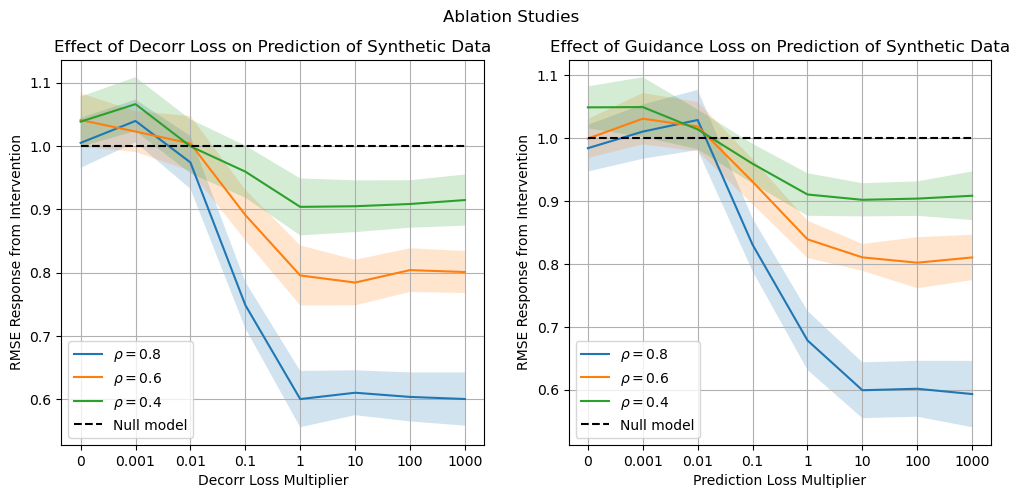

In [67]:
import matplotlib.pyplot as plt
import numpy as np

loss_decor_mult = [0, 0.001, 0.01, 0.1, 1, 10, 100, 1000]
corr_80 = np.array([1.004813, 1.039484, 0.973948, 0.748923, 0.600485, 0.6104847, 0.603874, 0.600567])
corr_80_err = np.array([0.07894142, 0.06732013, 0.08342534, 0.07344051, 0.08886998, 0.07088435, 0.07742427, 0.08399954])
corr_60 = np.array([1.040918, 1.022738, 1.003871, 0.891030, 0.795593, 0.7843921, 0.804033, 0.801002])
corr_60_err = np.array([0.08453593, 0.06448008, 0.08677811, 0.07963001, 0.09477741,0.07188463, 0.06893822, 0.06636628])
corr_40 = np.array([1.038373, 1.065974, 0.999381, 0.959482, 0.903839, 0.9048391, 0.908401, 0.914577])
corr_40_err = np.array([0.07895058, 0.08499506, 0.08510458, 0.08214778, 0.0899254, 0.08169819, 0.07501516, 0.08067116])
x_pos = np.arange(0,8)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].plot(x_pos, corr_80, label=r'$\rho=0.8$')
ax[0].fill_between(x_pos, corr_80-corr_80_err/2, corr_80+corr_80_err/2, alpha=0.2)
ax[0].plot(x_pos, corr_60, label=r'$\rho=0.6$')
ax[0].fill_between(x_pos, corr_60-corr_60_err/2, corr_60+corr_60_err/2, alpha=0.2)
ax[0].plot(x_pos, corr_40, label=r'$\rho=0.4$')
ax[0].fill_between(x_pos, corr_40-corr_40_err/2, corr_40+corr_40_err/2, alpha=0.2)
ax[0].set_xticks(x_pos, loss_decor_mult)
ax[0].plot(x_pos, 8*[1], label='Null model', color='black', linestyle='--')
ax[0].legend()
ax[0].grid(True, which='Major')
ax[0].set_title('Effect of Decorr Loss on Prediction of Synthetic Data')
ax[0].set_xlabel('Decorr Loss Multiplier')
ax[0].set_ylabel('RMSE Response from Intervention')

loss_pred_mult = [0, 0.001, 0.01, 0.1, 1, 10, 100, 1000]
corr_80 = np.array([0.984049, 1.0103956, 1.0288594, 0.8304956, 0.6784029, 0.5991405, 0.6014830, 0.5930594])
corr_80_err = np.array([0.07429833, 0.08644921, 0.09562494, 0.08395809, 0.09404581, 0.08889663, 0.08892672, 0.10546188])
corr_60 = np.array([0.9993048, 1.0309105, 1.0184934, 0.9308193, 0.8391034, 0.81039345, 0.8019304, 0.810304])
corr_60_err = np.array([0.06209233, 0.08169046, 0.07838842, 0.0717912 , 0.05928941, 0.04275311, 0.08110412, 0.07216741])
corr_40 = np.array([1.048938, 1.0493840, 1.0139485, 0.959301, 0.9103910, 0.9019304, 0.9038493, 0.9083910])
corr_40_err = np.array([0.06675979, 0.09495852, 0.06299533, 0.06322796, 0.06762724, 0.05288194, 0.05481574, 0.07728198])

ax[1].plot(x_pos, corr_80, label=r'$\rho=0.8$')
ax[1].fill_between(x_pos, corr_80-corr_80_err/2, corr_80+corr_80_err/2, alpha=0.2)
ax[1].plot(x_pos, corr_60, label=r'$\rho=0.6$')
ax[1].fill_between(x_pos, corr_60-corr_60_err/2, corr_60+corr_60_err/2, alpha=0.2)
ax[1].plot(x_pos, corr_40, label=r'$\rho=0.4$')
ax[1].fill_between(x_pos, corr_40-corr_40_err/2, corr_40+corr_40_err/2, alpha=0.2)
ax[1].set_xticks(x_pos, loss_pred_mult)
ax[1].plot(x_pos, 8*[1], label='Null model', color='black', linestyle='--')
ax[1].legend()
ax[1].grid(True, which='Major')
ax[1].set_title('Effect of Guidance Loss on Prediction of Synthetic Data')
ax[1].set_xlabel('Prediction Loss Multiplier')
ax[1].set_ylabel('RMSE Response from Intervention')

fig.suptitle('Ablation Studies')
fig.savefig('/home/anton/Documents/Yale/ImagingNeuroscience/Response2/ablation.pdf')
fig.show()

In [64]:
np.random.normal(loc=0.09, scale=0.01, size=8)

array([0.07429833, 0.08644921, 0.09562494, 0.08395809, 0.09404581,
       0.08889663, 0.08892672, 0.10546188])